In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
df = pd.read_excel('Dataset for Data Analytics.xlsx')

In [21]:
df.head()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   OrderID          1200 non-null   object        
 1   Date             1200 non-null   datetime64[ns]
 2   CustomerID       1200 non-null   object        
 3   Product          1200 non-null   object        
 4   Quantity         1200 non-null   int64         
 5   UnitPrice        1200 non-null   float64       
 6   ShippingAddress  1200 non-null   object        
 7   PaymentMethod    1200 non-null   object        
 8   OrderStatus      1200 non-null   object        
 9   TrackingNumber   1200 non-null   object        
 10  ItemsInCart      1200 non-null   int64         
 11  CouponCode       891 non-null    object        
 12  ReferralSource   1200 non-null   object        
 13  TotalPrice       1200 non-null   float64       
dtypes: datetime64[ns](1), float64(2), int64(

In [23]:
df.head(5)

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


In [24]:
df.isnull().sum()

,0
OrderID,0
Date,0
CustomerID,0
Product,0
Quantity,0
UnitPrice,0
ShippingAddress,0
PaymentMethod,0
OrderStatus,0
TrackingNumber,0


In [25]:
df["CouponCode"] = df["CouponCode"].fillna(
    "No Coupon / Missing"
)

print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
OrderID            0
Date               0
CustomerID         0
Product            0
Quantity           0
UnitPrice          0
ShippingAddress    0
PaymentMethod      0
OrderStatus        0
TrackingNumber     0
ItemsInCart        0
CouponCode         0
ReferralSource     0
TotalPrice         0
dtype: int64


In [8]:
# Convert Date into datetime format
df["Date"] = pd.to_datetime(
    df["Date"], errors="coerce"
)

# Remove exact duplicate rows if any exist
df = df.drop_duplicates().copy()

# Create additional date columns for analysis
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["YearMonth"] = df["Date"].dt.to_period("M").astype(str)

print("Data preparation completed!")
display(df.head())

Data preparation completed!


,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice,Year,Month,YearMonth
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10,2023,1,2023-01
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70,2024,8,2024-08
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40,2024,2,2024-02
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19,2023,10,2023-10
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04,2025,5,2025-05


In [9]:
# Mean, median, count and other statistics
numeric_columns = [
    "Quantity",
    "UnitPrice",
    "ItemsInCart",
    "TotalPrice"
]

print("Descriptive statistics:")
display(df[numeric_columns].describe().round(2))

# Calculate mean and median separately
for col in numeric_columns:
    print(f"\n{col}")
    print("Mean:", round(df[col].mean(), 2))
    print("Median:", round(df[col].median(), 2))
    print("Count:", df[col].count())

Descriptive statistics:


,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200.00,1200.00,1200.00,1200.00
mean,2.95,356.41,5.48,1053.97
std,1.41,197.18,2.28,819.86
min,1.00,11.39,1.00,11.39
25%,2.00,186.06,4.00,410.52
50%,3.00,364.21,5.00,823.62
75%,4.00,521.57,7.00,1578.48
max,5.00,699.93,10.00,3456.40



Quantity
Mean: 2.95
Median: 3.0
Count: 1200

UnitPrice
Mean: 356.41
Median: 364.21
Count: 1200

ItemsInCart
Mean: 5.48
Median: 5.0
Count: 1200

TotalPrice
Mean: 1053.97
Median: 823.62
Count: 1200


In [10]:
# Number of orders for each product
product_count = df["Product"].value_counts()

print("Orders by product:")
display(product_count.to_frame("Order Count"))

# Total order value by product
product_sales = (
    df.groupby("Product")["TotalPrice"]
    .agg(["count", "sum", "mean"])
    .round(2)
    .sort_values("sum", ascending=False)
)

product_sales.columns = [
    "Order Count", "Total Order Value", "Average Order Value"
]

display(product_sales)

# Order status distribution
print("Order status:")
display(df["OrderStatus"].value_counts().to_frame("Count"))

# Payment method distribution
print("Payment methods:")
display(df["PaymentMethod"].value_counts().to_frame("Count"))

# Referral source distribution
print("Referral sources:")
display(df["ReferralSource"].value_counts().to_frame("Count"))

Orders by product:


,Order Count
Product,
Printer,181
Tablet,179
Chair,178
Laptop,173
Desk,170
Monitor,163
Phone,156


,Order Count,Total Order Value,Average Order Value
Product,,,
Chair,178,195620.11,1098.99
Printer,181,195612.61,1080.73
Laptop,173,192126.56,1110.56
Tablet,179,186568.95,1042.28
Monitor,163,175651.41,1077.62
Desk,170,167459.93,985.06
Phone,156,151722.39,972.58


Order status:


,Count
OrderStatus,
Cancelled,250
Returned,247
Pending,237
Shipped,235
Delivered,231


Payment methods:


,Count
PaymentMethod,
Online,258
Cash,246
Credit Card,234
Debit Card,232
Gift Card,230


Referral sources:


,Count
ReferralSource,
Instagram,259
Email,250
Google,241
Facebook,228
Referral,222


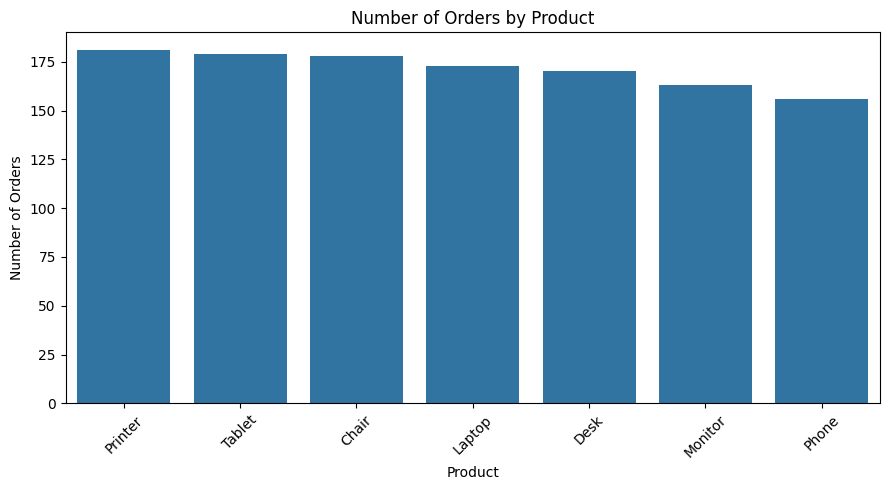

In [11]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Product",
    order=df["Product"].value_counts().index
)

plt.title("Number of Orders by Product")
plt.xlabel("Product")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

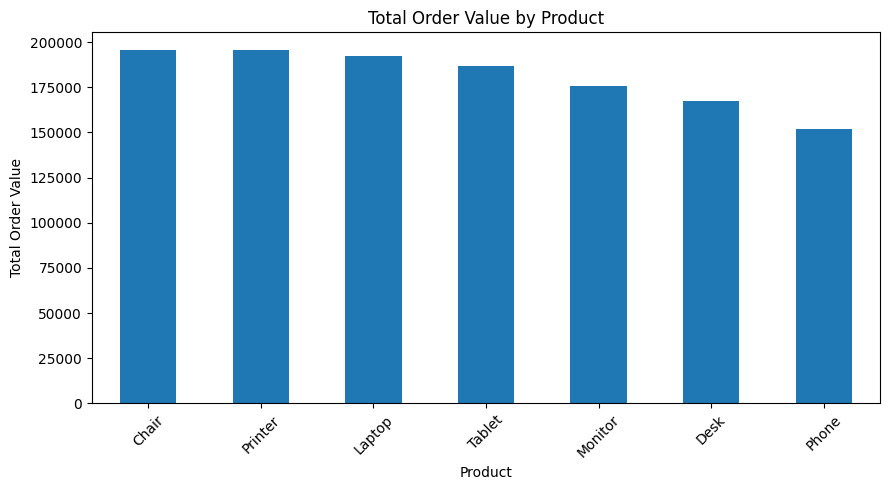

In [12]:
sales_by_product = (
    df.groupby("Product")["TotalPrice"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

sales_by_product.plot(kind="bar")

plt.title("Total Order Value by Product")
plt.xlabel("Product")
plt.ylabel("Total Order Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

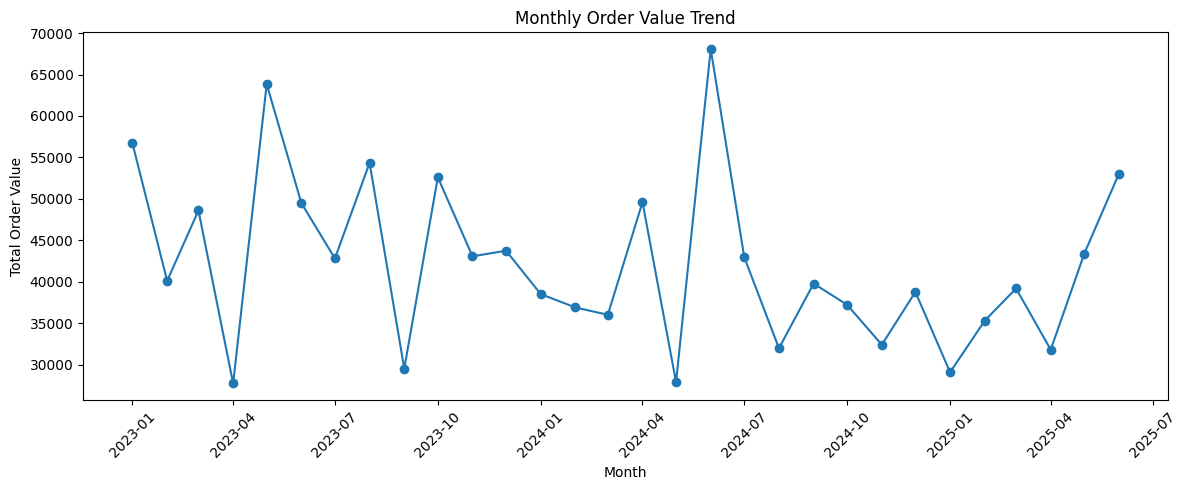

,Total Order Value
Date,
2023-01-01,56685.75
2023-02-01,40117.66
2023-03-01,48609.37
2023-04-01,27751.71
2023-05-01,63836.84
2023-06-01,49500.19
2023-07-01,42820.66
2023-08-01,54352.14
2023-09-01,29526.67


In [13]:
monthly_sales = (
    df.dropna(subset=["Date"])
    .set_index("Date")["TotalPrice"]
    .resample("MS")
    .sum()
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Order Value Trend")
plt.xlabel("Month")
plt.ylabel("Total Order Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly_sales.to_frame("Total Order Value"))

In [14]:
def find_outliers(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)

    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    outliers = data[
        (data[column] < lower_limit) |
        (data[column] > upper_limit)
    ]

    print(f"\nColumn: {column}")
    print("Q1:", round(q1, 2))
    print("Q3:", round(q3, 2))
    print("Lower limit:", round(lower_limit, 2))
    print("Upper limit:", round(upper_limit, 2))
    print("Number of outliers:", len(outliers))

    return outliers

price_outliers = find_outliers(df, "TotalPrice")

display(
    price_outliers[
        ["OrderID", "Product", "Quantity", "TotalPrice"]
    ].head(20)
)


Column: TotalPrice
Q1: 410.52
Q3: 1578.48
Lower limit: -1341.41
Upper limit: 3330.41
Number of outliers: 8


,OrderID,Product,Quantity,TotalPrice
107,ORD200107,Printer,5,3353.75
326,ORD200326,Laptop,5,3352.40
328,ORD200328,Tablet,5,3370.20
469,ORD200469,Chair,5,3384.90
632,ORD200632,Laptop,5,3390.80
789,ORD200789,Tablet,5,3456.40
1065,ORD201065,Printer,5,3334.00
1122,ORD201122,Monitor,5,3390.95


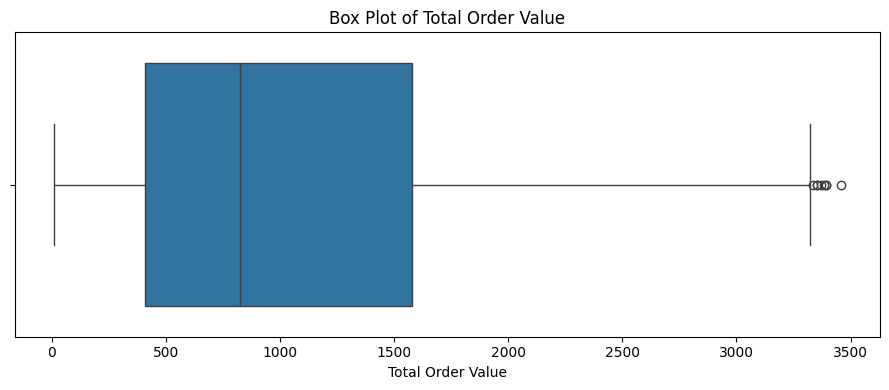

In [15]:
plt.figure(figsize=(9, 4))

sns.boxplot(x=df["TotalPrice"])

plt.title("Box Plot of Total Order Value")
plt.xlabel("Total Order Value")
plt.tight_layout()
plt.show()

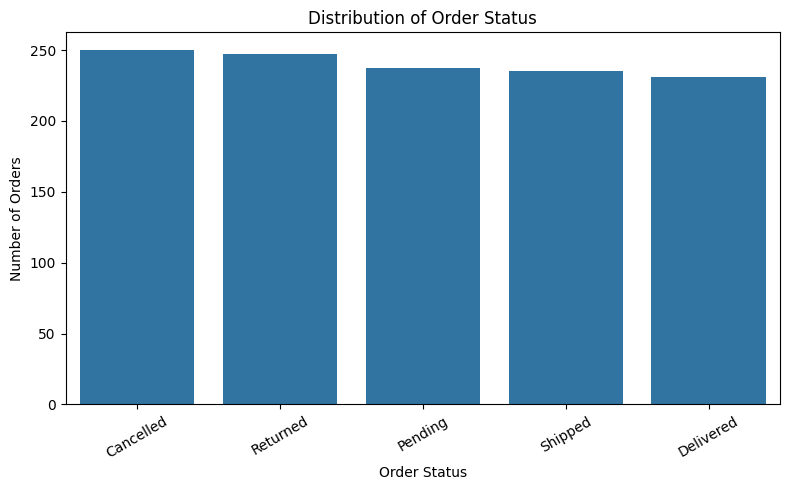

Order status percentages:


,Percentage
OrderStatus,
Cancelled,20.83
Returned,20.58
Pending,19.75
Shipped,19.58
Delivered,19.25


In [16]:
status_counts = df["OrderStatus"].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=status_counts.index,
    y=status_counts.values
)

plt.title("Distribution of Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Order status percentages:")
display(
    (df["OrderStatus"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage")
)

Correlation matrix:


,Quantity,UnitPrice,ItemsInCart,TotalPrice
Quantity,1.00,0.01,0.65,0.62
UnitPrice,0.01,1.00,0.00,0.72
ItemsInCart,0.65,0.00,1.00,0.39
TotalPrice,0.62,0.72,0.39,1.00


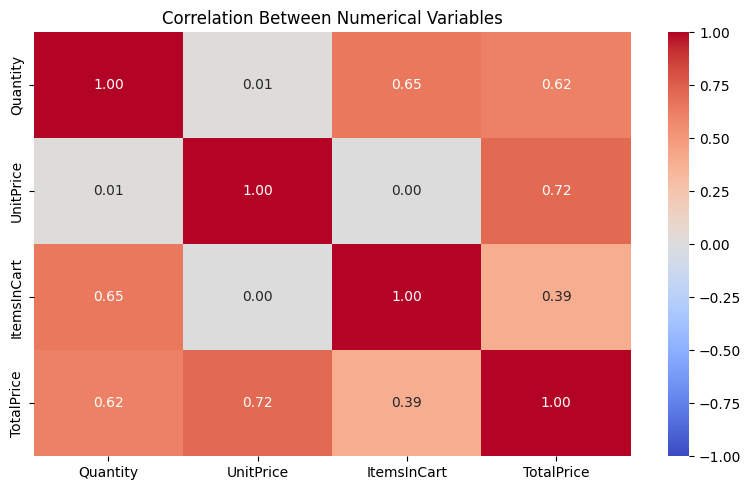

In [17]:
numeric_data = df[
    ["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice"]
]

correlation_matrix = numeric_data.corr()

print("Correlation matrix:")
display(correlation_matrix.round(2))

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

In [18]:
print("========== PROJECT 2 EDA SUMMARY ==========")

print("Total records:", len(df))
print("Total columns:", df.shape[1])
print("Unique order IDs:", df["OrderID"].nunique())
print("Unique customers:", df["CustomerID"].nunique())
print("Number of products:", df["Product"].nunique())

print(
    "Total recorded order value:",
    round(df["TotalPrice"].sum(), 2)
)

print(
    "Average order value:",
    round(df["TotalPrice"].mean(), 2)
)

print(
    "Most frequently ordered product:",
    df["Product"].value_counts().idxmax()
)

print(
    "Product with highest total order value:",
    df.groupby("Product")["TotalPrice"].sum().idxmax()
)

print(
    "Most common order status:",
    df["OrderStatus"].value_counts().idxmax()
)

print("===========================================")

========== PROJECT 2 EDA SUMMARY ==========
Total records: 1200
Total columns: 17
Unique order IDs: 1200
Unique customers: 1189
Number of products: 7
Total recorded order value: 1264761.96
Average order value: 1053.97
Most frequently ordered product: Printer
Product with highest total order value: Chair
Most common order status: Cancelled
